# 01 — Exploratory Data Analysis

Dataset: Kaggle "Game Recommendations on Steam" (`data/raw/`).

Goal: understand the four files well enough to make the design decisions in `docs/decisions.md`:
which signals exist, how sparse and skewed the interactions are, what cold start looks like,
and how to split data for offline evaluation.

Sections:
1. Setup and loading
2. Data quality (missing values, duplicates, joins)
3. Games
4. Game metadata (tags, descriptions)
5. Reviews: labels, hours, votes
6. Reviews over time
7. Sparsity and popularity
8. Cold start
9. Users file
10. Feasibility checks for the models and the evaluation
11. Conclusions

## 1. Setup and loading

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("..") / "data" / "raw"

# Plot style: one main hue, light grid, no top/right borders.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE]),
})
pd.set_option("display.float_format", "{:,.3f}".format)

The three small files load directly. Tags in the metadata file are lists, one JSON object per line.

In [2]:
games = pd.read_csv(DATA_DIR / "games.csv", parse_dates=["date_release"])
meta = pd.read_json(DATA_DIR / "games_metadata.json", lines=True)
users = pd.read_csv(DATA_DIR / "users.csv")

print("games:", games.shape)
print("meta: ", meta.shape)
print("users:", users.shape)
games.head()

games: (50872, 13)
meta:  (50872, 3)
users: (14306064, 3)


,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.990,9.990,0.000,True
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.990,2.990,0.000,True
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.990,14.990,0.000,True
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.990,14.990,0.000,True
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.990,11.990,0.000,True


In [3]:
meta.head()

,app_id,description,tags
0,13500,Enter the dark underworld of Prince of Persia ...,"[Action, Adventure, Parkour, Third Person, Gre..."
1,22364,,[Action]
2,113020,Monaco: What's Yours Is Mine is a single playe...,"[Co-op, Stealth, Indie, Heist, Local Co-Op, St..."
3,226560,Escape Dead Island is a Survival-Mystery adven...,"[Zombies, Adventure, Survival, Action, Third P..."
4,249050,Dungeon of the Endless is a Rogue-Like Dungeon...,"[Roguelike, Strategy, Tower Defense, Pixel Gra..."


In [4]:
users.head()

,user_id,products,reviews
0,7360263,359,0
1,14020781,156,1
2,8762579,329,4
3,4820647,176,4
4,5167327,98,2


`recommendations.csv` is 2GB / 41M rows. Setting small integer and float types up front keeps it to
roughly 1GB in memory instead of several GB with pandas defaults.

In [5]:
rec_dtypes = {
    "app_id": "int32",
    "helpful": "int32",
    "funny": "int32",
    "is_recommended": "bool",
    "hours": "float32",
    "user_id": "int32",
    "review_id": "int32",
}
recs = pd.read_csv(DATA_DIR / "recommendations.csv", dtype=rec_dtypes, parse_dates=["date"])

memory_gb = recs.memory_usage(deep=True).sum() / 1e9
print("recs:", recs.shape, f"- {memory_gb:.2f} GB in memory")
recs.head()

recs: (41154794, 8) - 1.36 GB in memory


,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,975370,0,0,2022-12-12,True,36.300,51580,0
1,304390,4,0,2017-02-17,False,11.500,2586,1
2,1085660,2,0,2019-11-17,True,336.500,253880,2
3,703080,0,0,2022-09-23,True,27.400,259432,3
4,526870,0,0,2021-01-10,True,7.900,23869,4


In [6]:
recs.describe()

,app_id,helpful,funny,date,hours,user_id,review_id
count,"41,154,794.000","41,154,794.000","41,154,794.000",41154794,"41,154,794.000","41,154,794.000","41,154,794.000"
mean,"603,272.359",3.203,1.058,2020-02-12 18:14:56.361187,100.602,"7,450,576.005","20,577,396.500"
min,10.000,0.000,0.000,2010-10-15 00:00:00,0.000,0.000,0.000
25%,"253,940.000",0.000,0.000,2018-10-29 00:00:00,7.800,"4,287,256.000","10,288,698.250"
50%,"435,150.000",0.000,0.000,2020-10-08 00:00:00,27.300,"7,546,445.500","20,577,396.500"
75%,"933,110.000",0.000,0.000,2021-12-05 00:00:00,99.200,"10,968,770.750","30,866,094.750"
max,"2,253,290.000","36,212.000","28,109.000",2022-12-31 00:00:00,"1,000.000","14,306,063.000","41,154,793.000"
std,"472,923.282",46.936,28.671,NaN,176.168,"4,010,685.033","11,880,365.842"


## 2. Data quality

### Missing values

In [7]:
tables = {"games": games, "meta": meta, "users": users, "recs": recs}
for name, table in tables.items():
    missing = table.isna().sum().sum()
    print(f"{name:6s} missing values: {missing}")

games  missing values: 0
meta   missing values: 0
users  missing values: 0


recs   missing values: 0


No NaNs does not mean no missing data: descriptions and tags can be empty strings / empty lists.

In [8]:
empty_description = meta["description"].str.len() == 0
no_tags = meta["tags"].str.len() == 0
print(f"empty description: {empty_description.sum():,} ({empty_description.mean():.1%})")
print(f"no tags:           {no_tags.sum():,} ({no_tags.mean():.1%})")
print(f"both empty:        {(empty_description & no_tags).sum():,}")

empty description: 10,373 (20.4%)
no tags:           1,244 (2.4%)
both empty:        1,229


### Duplicates

In [9]:
print("duplicate app_id in games:", games["app_id"].duplicated().sum())
print("duplicate app_id in meta: ", meta["app_id"].duplicated().sum())
print("duplicate user_id in users:", users["user_id"].duplicated().sum())
print("duplicate review_id in recs:", recs["review_id"].duplicated().sum())

same_user_same_game = recs.duplicated(subset=["user_id", "app_id"]).sum()
print("reviews with same (user, game) pair:", same_user_same_game)

duplicate app_id in games: 0
duplicate app_id in meta:  0


duplicate user_id in users: 0


duplicate review_id in recs: 0


reviews with same (user, game) pair: 21


In [10]:
duplicate_titles = games["title"].duplicated(keep=False)
print(f"games sharing a title with another game: {duplicate_titles.sum():,}")
games[duplicate_titles].sort_values("title")[["app_id", "title", "date_release", "user_reviews"]].head(10)

games sharing a title with another game: 233


,app_id,title,date_release,user_reviews
31705,1099550,3D Organon Anatomy,2019-07-17,70
7009,583620,3D Organon Anatomy,2017-06-23,98
24768,842420,A Walk in the Woods,2018-05-01,527
40919,557900,A Walk in the Woods,2020-04-21,83
13929,743640,Achievement Clicker,2017-11-17,2044
23216,1229730,Achievement Clicker,2020-02-11,45
47188,1990210,Achromatic,2022-06-13,42
39131,926170,Achromatic,2018-09-28,56
42692,871870,Alone,2018-06-21,31
28584,837930,Alone,2018-05-01,22


### Do the files join cleanly?

In [11]:
game_ids = set(games["app_id"])
meta_ids = set(meta["app_id"])
review_game_ids = set(recs["app_id"].unique())

print("games without metadata:          ", len(game_ids - meta_ids))
print("reviewed games missing from games:", len(review_game_ids - game_ids))
print("games with zero reviews:          ", len(game_ids - review_game_ids))

games without metadata:           0
reviewed games missing from games: 0
games with zero reviews:           13262


In [12]:
review_user_ids = pd.Series(recs["user_id"].unique())
in_users_file = review_user_ids.isin(users["user_id"])
print(f"review users missing from users.csv: {(~in_users_file).sum():,}")

users_without_reviews = ~users["user_id"].isin(review_user_ids)
print(f"users.csv users with no review rows: {users_without_reviews.sum():,} ({users_without_reviews.mean():.1%})")

review users missing from users.csv: 0


users.csv users with no review rows: 525,005 (3.7%)


## 3. Games

`games.csv` holds catalog facts: release date, platforms, Steam's rating bucket, the percentage of
positive reviews (`positive_ratio`), the total review count on Steam (`user_reviews`) and price.

In [13]:
games.describe()

,app_id,date_release,positive_ratio,user_reviews,price_final,price_original,discount
count,"50,872.000",50872,"50,872.000","50,872.000","50,872.000","50,872.000","50,872.000"
mean,"1,055,223.805",2019-03-13 03:53:57.112753,77.052,"1,824.425",8.620,8.727,5.592
min,10.000,1997-06-30 00:00:00,0.000,10.000,0.000,0.000,0.000
25%,"528,737.500",2017-03-21 00:00:00,67.000,19.000,0.990,0.990,0.000
50%,"986,085.000",2019-08-23 00:00:00,81.000,49.000,4.990,4.990,0.000
75%,"1,524,895.000",2021-09-21 00:00:00,91.000,206.000,10.990,11.990,0.000
max,"2,599,300.000",2023-10-24 00:00:00,100.000,"7,494,460.000",299.990,299.990,90.000
std,"610,324.945",NaN,18.254,"40,073.522",11.514,11.507,18.607


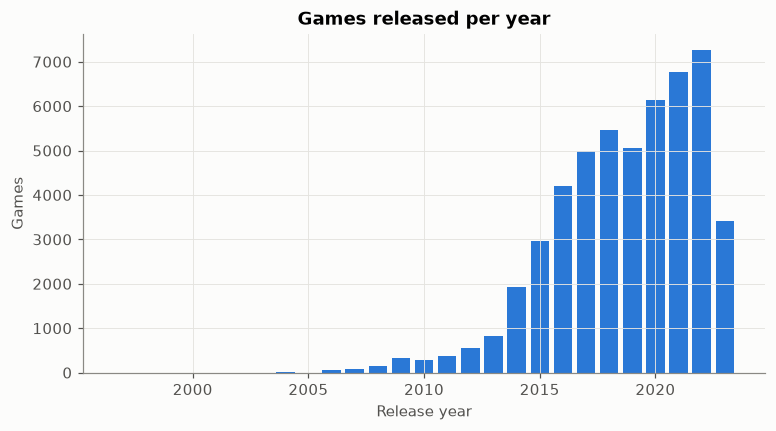

released 2018 or later: 67.1%


In [14]:
release_year = games["date_release"].dt.year
games_per_year = release_year.value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(games_per_year.index, games_per_year.values, color=BLUE, width=0.8)
ax.set_title("Games released per year")
ax.set_xlabel("Release year")
ax.set_ylabel("Games")
plt.show()

print(f"released 2018 or later: {(release_year >= 2018).mean():.1%}")

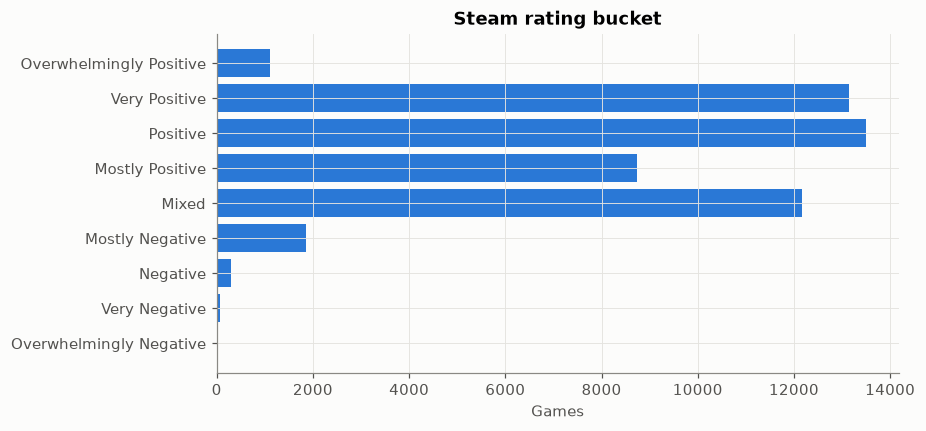

In [15]:
rating_order = [
    "Overwhelmingly Negative", "Very Negative", "Negative", "Mostly Negative", "Mixed",
    "Mostly Positive", "Positive", "Very Positive", "Overwhelmingly Positive",
]
rating_counts = games["rating"].value_counts().reindex(rating_order)

fig, ax = plt.subplots()
ax.barh(rating_counts.index, rating_counts.values, color=BLUE)
ax.set_title("Steam rating bucket")
ax.set_xlabel("Games")
plt.show()

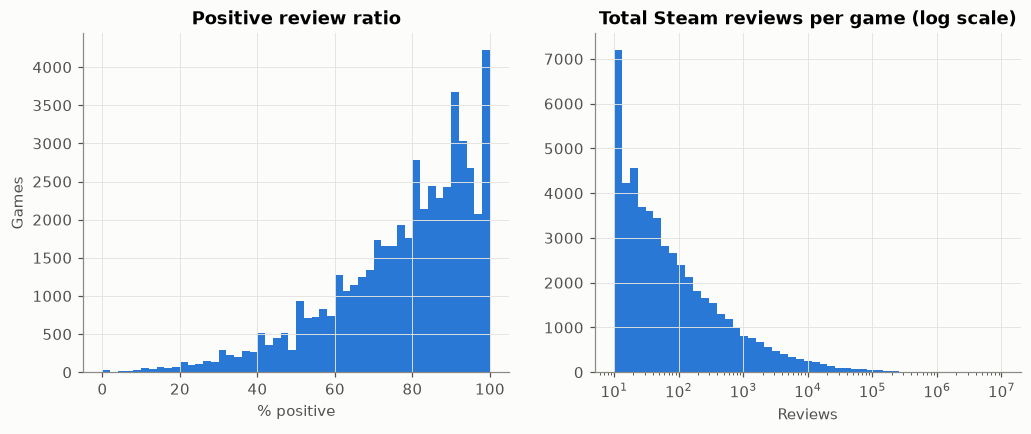

minimum user_reviews in games.csv: 10


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(games["positive_ratio"], bins=50, color=BLUE)
axes[0].set_title("Positive review ratio")
axes[0].set_xlabel("% positive")
axes[0].set_ylabel("Games")

review_bins = np.logspace(1, 7, 50)
axes[1].hist(games["user_reviews"], bins=review_bins, color=BLUE)
axes[1].set_xscale("log")
axes[1].set_title("Total Steam reviews per game (log scale)")
axes[1].set_xlabel("Reviews")
plt.show()

print("minimum user_reviews in games.csv:", games["user_reviews"].min())

free games: 17.9%
discounted right now: 9.8%


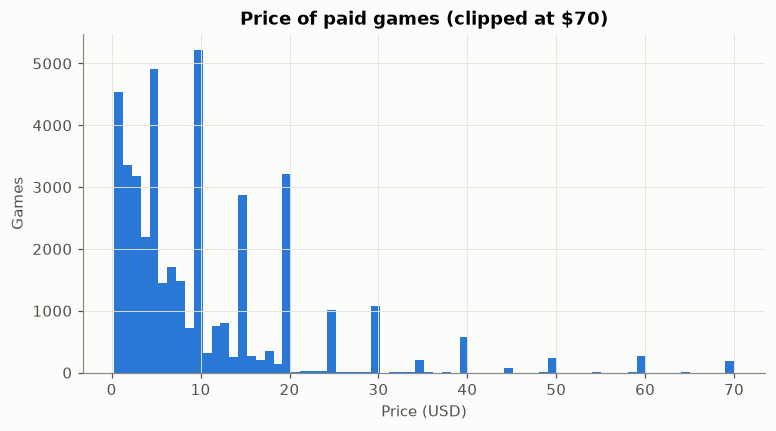

In [17]:
is_free = games["price_final"] == 0
print(f"free games: {is_free.mean():.1%}")
print(f"discounted right now: {(games['discount'] > 0).mean():.1%}")

paid_prices = games.loc[~is_free, "price_final"]
fig, ax = plt.subplots()
ax.hist(paid_prices.clip(upper=70), bins=70, color=BLUE)
ax.set_title("Price of paid games (clipped at $70)")
ax.set_xlabel("Price (USD)")
ax.set_ylabel("Games")
plt.show()

In [18]:
platform_share = games[["win", "mac", "linux", "steam_deck"]].mean()
print(platform_share)

win          0.984
mac          0.256
linux        0.178
steam_deck   1.000
dtype: float64


Is the catalog only games? Titles that look like soundtracks, DLC or bundles would be odd
recommendations.

In [19]:
# Match whole words only (\b = word boundary), otherwise "OST" also matches "Ghost", "Lost", ...
non_game_words = ["Soundtrack", "OST", "DLC", "Season Pass", "Artbook"]
looks_non_game = pd.Series(False, index=games.index)
for word in non_game_words:
    matches = games["title"].str.contains(rf"\b{word}\b", regex=True)
    looks_non_game = looks_non_game | matches
    print(f"{word:12s} {matches.sum():5,} titles")

non_game_ids = games.loc[looks_non_game, "app_id"]
reviews_on_non_games = recs["app_id"].isin(non_game_ids)
print(f"\ntitles matching any word: {looks_non_game.sum():,}")
print(f"reviews on those titles:  {reviews_on_non_games.sum():,} ({reviews_on_non_games.mean():.3%} of all reviews)")

games.loc[looks_non_game, ["app_id", "title", "user_reviews"]].head(8)

Soundtrack     783 titles
OST            113 titles
DLC            543 titles
Season Pass    143 titles


Artbook         60 titles



titles matching any word: 1,623
reviews on those titles:  3,615 (0.009% of all reviews)


,app_id,title,user_reviews
30,458790,The House in Fata Morgana Original Soundtrack,32
31,462280,Offworld Trading Company - Soundtrack DLC,10
80,436550,Homeworld: Deserts of Kharak - Soundtrack,23
82,439500,LEGO® MARVEL's Avengers DLC - The Masters of E...,16
109,610070,Rain World - Soundtrack,30
147,584096,Little Nightmares The Hideaway DLC,309
149,292050,Valkyrie Hat (or 'Buy Us Coffee') DLC for Secr...,43
180,453400,Squad - Original Soundtrack Vol. 1 & 2,97


Some matches are real games ("... - Soundtrack Edition" bundles, DLC-heavy titles), so this is a rough
filter. Still, these titles get almost no reviews, so collaborative filtering will never recommend them;
only a content-based retriever could, which is where a filter matters.

## 4. Game metadata: tags and descriptions

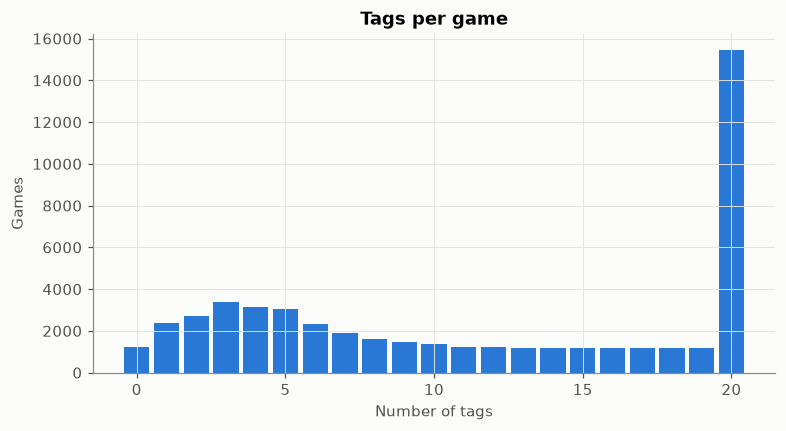

games with the maximum of 20 tags: 30.4%


In [20]:
tags_per_game = meta["tags"].str.len()

fig, ax = plt.subplots()
ax.hist(tags_per_game, bins=range(0, 22), color=BLUE, align="left", rwidth=0.85)
ax.set_title("Tags per game")
ax.set_xlabel("Number of tags")
ax.set_ylabel("Games")
plt.show()

print(f"games with the maximum of 20 tags: {(tags_per_game == 20).mean():.1%}")

unique tags: 441
tags used by fewer than 50 games: 44


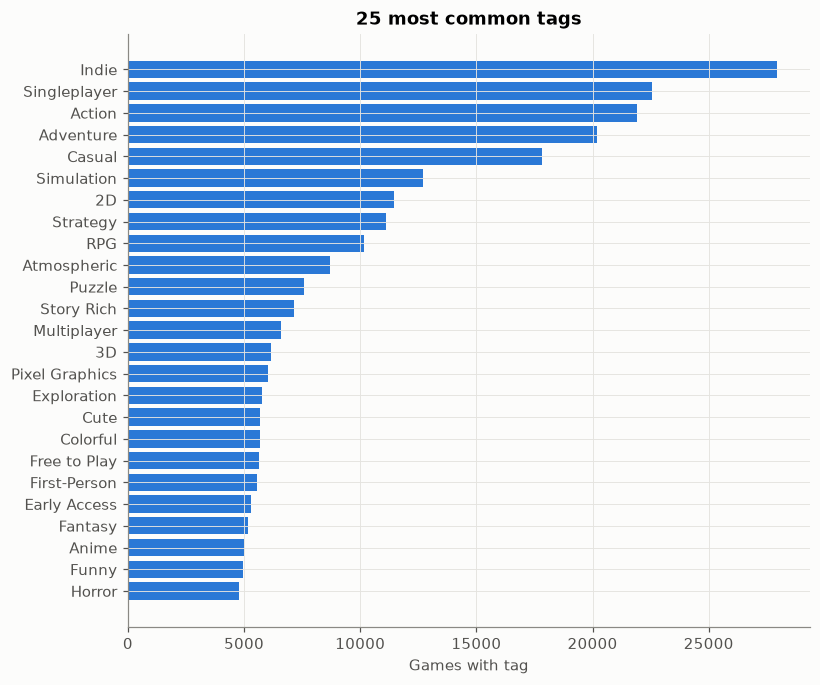

In [21]:
all_tags = meta["tags"].explode().dropna()
tag_counts = all_tags.value_counts()
print("unique tags:", len(tag_counts))
print(f"tags used by fewer than 50 games: {(tag_counts < 50).sum()}")

top_tags = tag_counts.head(25).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_tags.index, top_tags.values, color=BLUE)
ax.set_title("25 most common tags")
ax.set_xlabel("Games with tag")
plt.show()

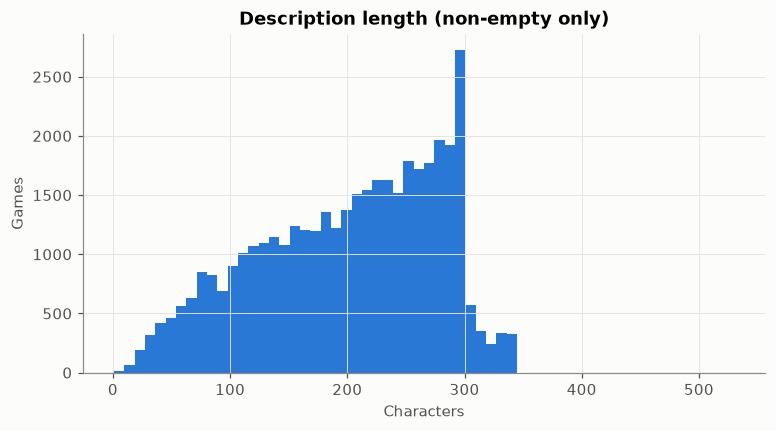

description length quantiles (non-empty):
0.100    87.000
0.500   211.000
0.900   293.000
1.000   530.000
Name: description, dtype: float64


In [22]:
description_length = meta["description"].str.len()
non_empty_lengths = description_length[description_length > 0]

fig, ax = plt.subplots()
ax.hist(non_empty_lengths, bins=60, color=BLUE)
ax.set_title("Description length (non-empty only)")
ax.set_xlabel("Characters")
ax.set_ylabel("Games")
plt.show()

print("description length quantiles (non-empty):")
print(non_empty_lengths.quantile([0.1, 0.5, 0.9, 1.0]))

## 5. Reviews: labels, hours, votes

Each row is one user's review of one game: thumbs up/down (`is_recommended`), hours played when
reviewing, and helpful/funny votes from other users.

In [23]:
positive_share = recs["is_recommended"].mean()
print(f"recommended:     {positive_share:.1%}")
print(f"not recommended: {1 - positive_share:.1%}  ({(~recs['is_recommended']).sum():,} reviews)")

user_has_negative = recs.groupby("user_id")["is_recommended"].min() == False
print(f"users with at least one negative review: {user_has_negative.mean():.1%}")

recommended:     85.8%
not recommended: 14.2%  (5,850,396 reviews)


users with at least one negative review: 23.1%


### Hours played

hours == 0:    0.43%


hours == 1000: 26 reviews


max hours:     1000.0


0.100     2.100
0.250     7.800
0.500    27.300
0.750    99.200
0.900   304.000
0.990   864.500
Name: hours, dtype: float64


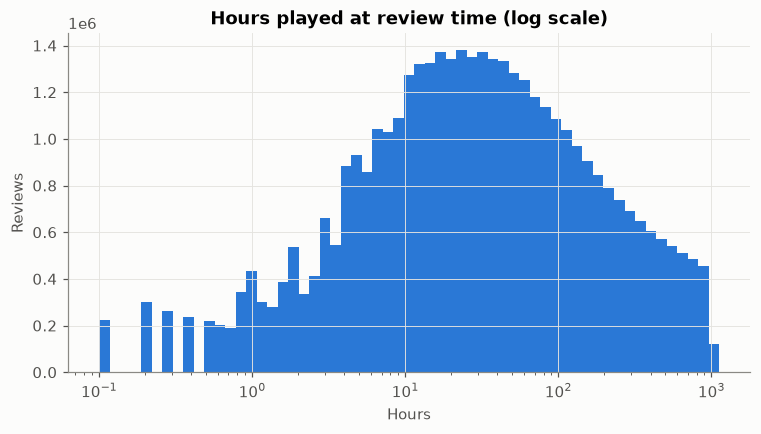

In [24]:
hours = recs["hours"]
print(f"hours == 0:    {(hours == 0).mean():.2%}")
print(f"hours == 1000: {(hours == 1000).sum()} reviews")
print(f"max hours:     {hours.max()}")
print(hours.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

hour_bins = np.logspace(-1, 3.05, 60)
fig, ax = plt.subplots()
ax.hist(hours[hours > 0], bins=hour_bins, color=BLUE)
ax.set_xscale("log")
ax.set_title("Hours played at review time (log scale)")
ax.set_xlabel("Hours")
ax.set_ylabel("Reviews")
plt.show()

Does playtime relate to the thumbs up/down? If yes, hours carry useful signal.

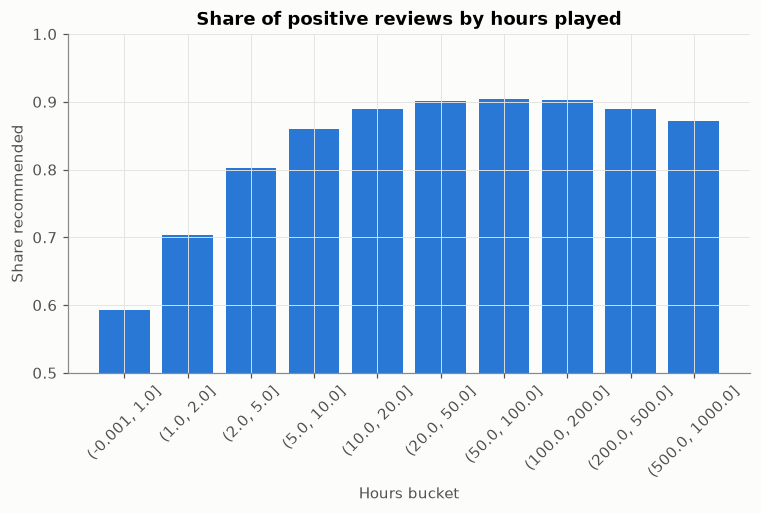

hours
(-0.001, 1.0]     0.592
(1.0, 2.0]        0.704
(2.0, 5.0]        0.803
(5.0, 10.0]       0.861
(10.0, 20.0]      0.889
(20.0, 50.0]      0.901
(50.0, 100.0]     0.905
(100.0, 200.0]    0.903
(200.0, 500.0]    0.890
(500.0, 1000.0]   0.872
Name: is_recommended, dtype: float64

median hours by label:


is_recommended
False   11.100
True    30.300
Name: hours, dtype: float32


In [25]:
hour_edges = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
hour_bucket = pd.cut(recs["hours"], bins=hour_edges, include_lowest=True)
positive_by_hours = recs.groupby(hour_bucket, observed=True)["is_recommended"].mean()

fig, ax = plt.subplots()
ax.bar(positive_by_hours.index.astype(str), positive_by_hours.values, color=BLUE)
ax.set_ylim(0.5, 1.0)
ax.set_title("Share of positive reviews by hours played")
ax.set_xlabel("Hours bucket")
ax.set_ylabel("Share recommended")
ax.tick_params(axis="x", rotation=45)
plt.show()

print(positive_by_hours)
print("\nmedian hours by label:")
print(recs.groupby("is_recommended")["hours"].median())

### Helpful and funny votes

In [26]:
print(f"reviews with 0 helpful votes: {(recs['helpful'] == 0).mean():.1%}")
print(f"reviews with 0 funny votes:   {(recs['funny'] == 0).mean():.1%}")

reviews with 0 helpful votes: 78.9%


reviews with 0 funny votes:   93.7%


## 6. Reviews over time

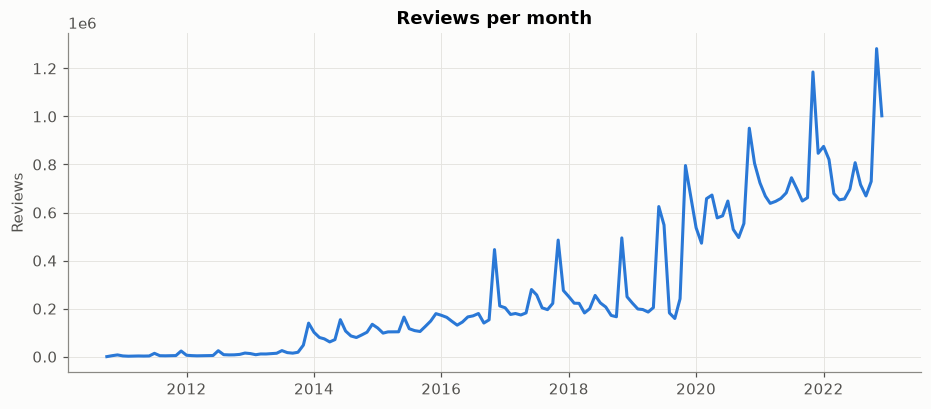

first review: 2010-10-15  last review: 2022-12-31


In [27]:
reviews_per_month = recs.groupby(recs["date"].dt.to_period("M")).size()
reviews_per_month.index = reviews_per_month.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(reviews_per_month.index, reviews_per_month.values, color=BLUE, linewidth=2)
ax.set_title("Reviews per month")
ax.set_ylabel("Reviews")
plt.show()

print("first review:", recs["date"].min().date(), " last review:", recs["date"].max().date())

In [28]:
review_year = recs["date"].dt.year
positive_by_year = recs.groupby(review_year)["is_recommended"].mean()
reviews_by_year = review_year.value_counts().sort_index()

summary_by_year = pd.DataFrame({"reviews": reviews_by_year, "share_positive": positive_by_year})
summary_by_year

,reviews,share_positive
date,,
2010,12201,0.974
2011,71546,0.965
2012,101726,0.960
2013,335335,0.931
2014,1143156,0.880
2015,1477099,0.835
2016,2226413,0.835
2017,2834442,0.822
2018,2845219,0.813


For a time-based train/test split we need a cutoff date. These quantiles show which date leaves
roughly the last 20% / 10% / 5% of reviews for testing.

In [29]:
recs["date"].quantile([0.8, 0.9, 0.95])

0.800   2022-02-16
0.900   2022-08-13
0.950   2022-11-10
Name: date, dtype: datetime64[us]

## 7. Sparsity and popularity

In [30]:
n_users = recs["user_id"].nunique()
n_games = recs["app_id"].nunique()
density = len(recs) / (n_users * n_games)
print(f"users: {n_users:,}   games: {n_games:,}   reviews: {len(recs):,}")
print(f"density: {density:.2e}  (share of user x game cells that have a review)")

users: 13,781,059   games: 37,610   reviews: 41,154,794
density: 7.94e-05  (share of user x game cells that have a review)


### Reviews per user

In [31]:
reviews_per_user = recs["user_id"].value_counts()

rows = []
for threshold in [1, 2, 3, 5, 10, 20, 50, 100]:
    n = (reviews_per_user >= threshold).sum()
    rows.append({"min_reviews": threshold, "users": n, "share_of_users": n / n_users})
pd.DataFrame(rows)

,min_reviews,users,share_of_users
0,1,13781059,1.000
1,2,6208032,0.450
2,3,3771654,0.274
3,5,1910831,0.139
4,10,680812,0.049
5,20,213364,0.015
6,50,37160,0.003
7,100,8364,0.001


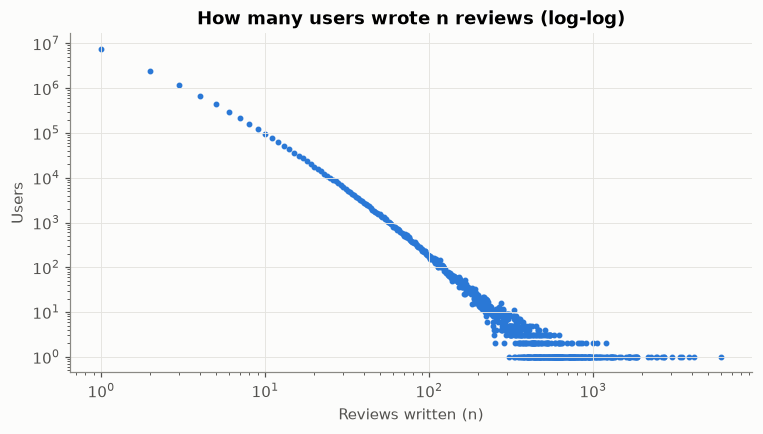

most active users:
user_id
11764552    6045
5112758     4152
11656130    3840
5669734     3479
11553593    3392
Name: count, dtype: int64


In [32]:
users_by_count = reviews_per_user.value_counts().sort_index()

fig, ax = plt.subplots()
ax.scatter(users_by_count.index, users_by_count.values, s=8, color=BLUE)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("How many users wrote n reviews (log-log)")
ax.set_xlabel("Reviews written (n)")
ax.set_ylabel("Users")
plt.show()

print("most active users:")
print(reviews_per_user.head(5))

### Reviews per game and the long tail

In [33]:
reviews_per_game = recs["app_id"].value_counts()

rows = []
for threshold in [1, 10, 50, 100, 1000, 10000]:
    rows.append({"min_reviews": threshold, "games": (reviews_per_game >= threshold).sum()})
pd.DataFrame(rows)

,min_reviews,games
0,1,37610
1,10,31226
2,50,16977
3,100,12460
4,1000,3685
5,10000,738


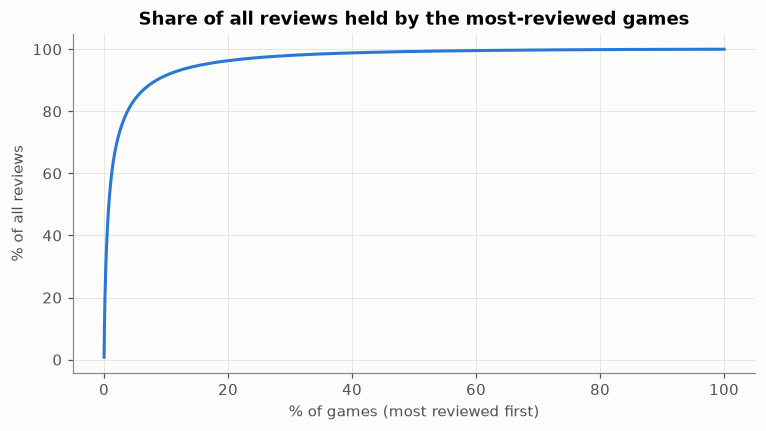

top  1% of games hold 55.6% of reviews
top  5% of games hold 84.0% of reviews
top 10% of games hold 91.6% of reviews
top 20% of games hold 96.3% of reviews


In [34]:
sorted_counts = reviews_per_game.sort_values(ascending=False).values
cumulative_share = np.cumsum(sorted_counts) / sorted_counts.sum()
share_of_games = np.arange(1, len(sorted_counts) + 1) / len(sorted_counts)

fig, ax = plt.subplots()
ax.plot(share_of_games * 100, cumulative_share * 100, color=BLUE, linewidth=2)
ax.set_title("Share of all reviews held by the most-reviewed games")
ax.set_xlabel("% of games (most reviewed first)")
ax.set_ylabel("% of all reviews")
plt.show()

for top_pct in [1, 5, 10, 20]:
    n_top = int(len(sorted_counts) * top_pct / 100)
    print(f"top {top_pct:2d}% of games hold {cumulative_share[n_top - 1]:.1%} of reviews")

In [35]:
top_games = reviews_per_game.head(10).rename("reviews").to_frame()
top_games = top_games.join(games.set_index("app_id")[["title"]])
top_games

,reviews,title
app_id,,
440,319492,Team Fortress 2
252490,270684,Rust
1091500,226414,Cyberpunk 2077
730,219737,Counter-Strike: Global Offensive
570,216914,Dota 2
444090,204176,Paladins®
292030,204166,The Witcher® 3: Wild Hunt
377160,196789,Fallout 4
374320,190157,DARK SOULS™ III


### Does the sample agree with Steam?

`games.positive_ratio` is Steam's own number. If the share of positive reviews in our sample is close to
it, the sample is representative of how players feel about each game.

games with >= 100 sample reviews: 12,460
correlation of sample positive share with Steam positive_ratio: 0.957


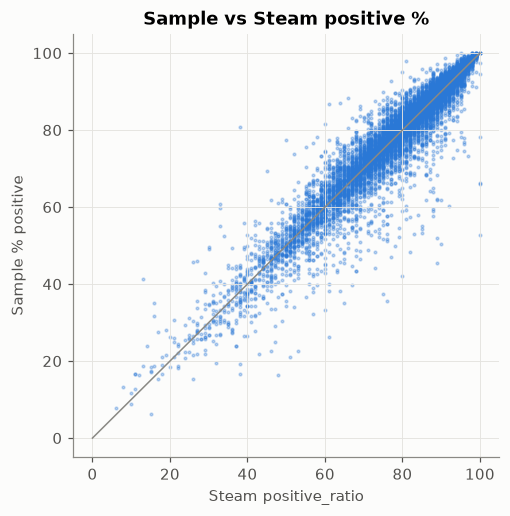

In [36]:
per_game = recs.groupby("app_id").agg(
    sample_reviews=("is_recommended", "size"),
    sample_positive=("is_recommended", "mean"),
)
per_game = per_game.join(games.set_index("app_id")[["positive_ratio", "user_reviews"]])
well_reviewed = per_game[per_game["sample_reviews"] >= 100]

correlation = well_reviewed["sample_positive"].corr(well_reviewed["positive_ratio"] / 100)
print(f"games with >= 100 sample reviews: {len(well_reviewed):,}")
print(f"correlation of sample positive share with Steam positive_ratio: {correlation:.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(well_reviewed["positive_ratio"], well_reviewed["sample_positive"] * 100, s=3, alpha=0.3, color=BLUE)
ax.plot([0, 100], [0, 100], color="#8a8984", linewidth=1)
ax.set_title("Sample vs Steam positive %")
ax.set_xlabel("Steam positive_ratio")
ax.set_ylabel("Sample % positive")
plt.show()

## 8. Cold start: games with no reviews in the sample

In [37]:
reviewed = games["app_id"].isin(review_game_ids)
cold_games = games[~reviewed]
warm_games = games[reviewed]

print(f"cold games: {len(cold_games):,} ({len(cold_games) / len(games):.1%} of catalog)")
print("\nmedian Steam user_reviews:  cold", cold_games["user_reviews"].median(), " warm", warm_games["user_reviews"].median())
print(f"cold games released after the last review date (2022-12-31): {(cold_games['date_release'] > '2022-12-31').sum():,}")

cold games: 13,262 (26.1% of catalog)

median Steam user_reviews:  cold 32.0  warm 59.0
cold games released after the last review date (2022-12-31): 3,263


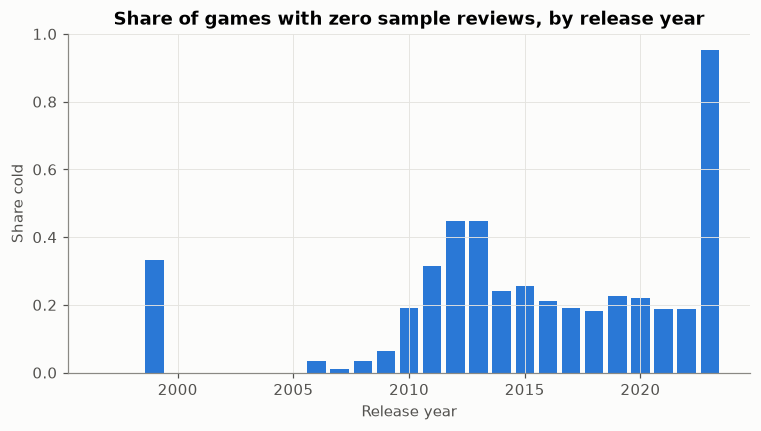

In [38]:
cold_by_year = cold_games["date_release"].dt.year.value_counts().sort_index()
all_by_year = games["date_release"].dt.year.value_counts().sort_index()
cold_share_by_year = (cold_by_year / all_by_year).fillna(0)

fig, ax = plt.subplots()
ax.bar(cold_share_by_year.index, cold_share_by_year.values, color=BLUE, width=0.8)
ax.set_title("Share of games with zero sample reviews, by release year")
ax.set_xlabel("Release year")
ax.set_ylabel("Share cold")
plt.show()

Cold games still need content to be recommendable. How many have usable metadata?

In [39]:
cold_meta = meta[meta["app_id"].isin(cold_games["app_id"])]
cold_has_tags = cold_meta["tags"].str.len() > 0
cold_has_description = cold_meta["description"].str.len() > 0
print(f"cold games with tags:        {cold_has_tags.mean():.1%}")
print(f"cold games with description: {cold_has_description.mean():.1%}")

cold games with tags:        95.0%
cold games with description: 26.4%


## 9. Users file

`users.csv` only has counts per user: `products` (games owned) and `reviews` (reviews written).
Check whether `reviews` matches the rows we actually have.

In [40]:
users.describe()

,user_id,products,reviews
count,"14,306,064.000","14,306,064.000","14,306,064.000"
mean,"7,153,031.500",116.373,2.877
std,"4,129,805.095",243.851,7.987
min,0.000,0.000,0.000
25%,"3,576,515.750",23.000,1.000
50%,"7,153,031.500",55.000,1.000
75%,"10,729,547.250",127.000,3.000
max,"14,306,063.000","32,214.000","6,045.000"


In [41]:
actual_reviews = reviews_per_user.rename("rows_in_recs")
users_check = users.set_index("user_id").join(actual_reviews, how="inner")
matches = users_check["reviews"] == users_check["rows_in_recs"]
print(f"users where users.reviews == rows in recommendations.csv: {matches.mean():.1%}")
print(f"users where users.reviews >  rows in recommendations.csv: {(users_check['reviews'] > users_check['rows_in_recs']).mean():.1%}")

users where users.reviews == rows in recommendations.csv: 100.0%
users where users.reviews >  rows in recommendations.csv: 0.0%


## 10. Feasibility checks for the models and the evaluation

### Users usable for training / evaluation

The app takes 3–5 liked games as input. To mimic that offline, a user needs several positive reviews:
some become seeds, at least one is held out as the target.

In [42]:
positives = recs[recs["is_recommended"]]
positives_per_user = positives["user_id"].value_counts()

for threshold in [3, 5, 6, 10]:
    print(f"users with >= {threshold:2d} positive reviews: {(positives_per_user >= threshold).sum():,}")

users with >=  3 positive reviews: 3,304,348
users with >=  5 positive reviews: 1,624,066
users with >=  6 positive reviews: 1,236,798
users with >= 10 positive reviews: 548,339


With a time split at the 90% date: how many users have at least 3 positives before the cutoff
(enough for seeds) and at least 1 positive after it (a target)?

In [43]:
cutoff = recs["date"].quantile(0.9)
print("cutoff date:", cutoff.date())

before = positives[positives["date"] < cutoff]
after = positives[positives["date"] >= cutoff]
positives_before = before["user_id"].value_counts()
positives_after = after["user_id"].value_counts()

has_seeds = positives_before[positives_before >= 3].index
has_target = positives_after.index
eval_users = has_seeds.intersection(has_target)
print(f"users with >= 3 positives before cutoff:            {len(has_seeds):,}")
print(f"... and >= 1 positive after cutoff (eval-ready):    {len(eval_users):,}")

cutoff date: 2022-08-13


users with >= 3 positives before cutoff:            2,967,885
... and >= 1 positive after cutoff (eval-ready):    759,669


In [44]:
target_games = after[after["user_id"].isin(eval_users)]["app_id"]
seen_before = set(before["app_id"].unique())
new_target_games = ~target_games.isin(seen_before)
print(f"target reviews on games with no positive review before cutoff: {new_target_games.mean():.2%}")

new_target_ids = target_games[new_target_games]
release_dates = games.set_index("app_id")["date_release"]
released_after_cutoff = new_target_ids.map(release_dates) >= cutoff
print(f"... of which released on/after the cutoff: {released_after_cutoff.mean():.1%}")

target reviews on games with no positive review before cutoff: 21.55%
... of which released on/after the cutoff: 99.7%


In [45]:
titles = games.set_index("app_id")["title"]
most_common_new_targets = new_target_ids.value_counts().head(8).rename("target_reviews").to_frame()
most_common_new_targets["title"] = most_common_new_targets.index.map(titles)
most_common_new_targets

,target_reviews,title
app_id,,
1938090,29748,Call of Duty®
1361210,13237,Warhammer 40000: Darktide
1687950,9244,Persona 5 Royal
975370,7387,Dwarf Fortress
529340,6238,Victoria 3
1583720,5592,Entropy : Zero 2
1942280,5413,Brotato
1237320,5000,Sonic Frontiers


### Cost of item-item co-occurrence

Co-occurrence counts every pair of games a user liked. A user with n positive reviews creates
n·(n−1)/2 pairs, so a handful of very heavy users can dominate both the cost and the counts.

In [46]:
n = positives_per_user.astype("int64")
pairs_per_user = n * (n - 1) // 2
total_pairs = pairs_per_user.sum()
print(f"total liked-pairs across users: {total_pairs:,}")

top_1pct = positives_per_user.head(int(len(positives_per_user) * 0.01)).index
share_from_top = pairs_per_user[top_1pct].sum() / total_pairs
print(f"share of pairs from the 1% most active users: {share_from_top:.1%}")

capped_n = n.clip(upper=100)
capped_pairs = (capped_n * (capped_n - 1) // 2).sum()
print(f"pairs if each user is capped at 100 positives: {capped_pairs:,}")

total liked-pairs across users: 320,697,841


share of pairs from the 1% most active users: 78.9%


pairs if each user is capped at 100 positives: 188,658,852


## 11. Conclusions

### What signals we have

| Signal | Finding | Use |
|---|---|---|
| `is_recommended` | 85.8% positive; 5.85M negatives; 23% of users wrote at least one negative | positives = "liked"; negatives = hard negatives for the ranker |
| `hours` | strongly tied to the label: under 1h only 59% positive, 20–200h about 90%. Median 11h for negative reviews vs 30h for positive | confidence weight and ranker feature |
| `helpful` / `funny` | 79% / 94% of reviews have zero votes | weak; skip for now |
| tags | 97.6% of games have tags; 441 unique; median 11 per game, 30% hit the 20-tag limit | **main content signal** |
| description | 20% empty; short when present (median 211 chars, max 530) | secondary content signal |
| `positive_ratio` | matches the sample closely (correlation 0.96 on games with ≥100 sample reviews) | trustworthy quality feature |
| `price`, release date, platforms | normal; 18% free; 67% released 2018+ | ranker features |
| `steam_deck` | `True` for 100% of games | **useless, drop** |
| `users.csv` | `reviews` equals the user's row count in `recommendations.csv` for 100% of users; nothing else per user | **drop for modeling** |

### Data quality

- No NaNs. Joins are clean: every reviewed game is in `games.csv`, every game has metadata, every reviewer is in `users.csv`.
- 21 duplicate (user, game) reviews → drop.
- 233 games share a title with a different game → `app_id` is the key; the app must show the release year to disambiguate.
- ~1.6k titles look like soundtracks / DLC / season passes, but together they get only a few thousand reviews.
  Collaborative filtering will ignore them; the content retriever should filter them out.
- Catalog only contains games with ≥10 Steam reviews (`user_reviews` min is 10).
- `hours` tops out at 1000 with only 26 rows at exactly 1000, so there is no large pile-up from capping.

### Sparsity and popularity

- Density 7.9e-5. 55% of users wrote one review; 1.9M users (13.9%) wrote ≥5.
- Top 1% of games hold 56% of reviews; top 10% hold 92%. The head is TF2, Rust, Cyberpunk 2077, CS:GO, Dota 2.
  → Without correction, every method will recommend the same blockbusters. Normalize co-occurrence,
  penalize popularity, measure coverage.
- 31k games have ≥10 reviews, 12.5k have ≥100: enough for collaborative filtering on the head and torso.

### Cold start

- 13,262 games (26% of the catalog) have no reviews at all; 3,263 of them came out after the last review date.
- Cold games have tags 95% of the time but descriptions only 26% of the time → the content retriever must rely on tags.

### Time and evaluation

- Review volume grows every year (2022 alone has 9.6M). The 90% date quantile is 2022-08-13.
- The share of positive reviews drifts by year (97% in 2010, 81% in 2018, 85% in 2022): mild label drift,
  another reason to split by time.
- Splitting at 2022-08-13: 2.97M users have ≥3 positives before the cutoff, and 760k of them also have
  a positive after it. Plenty; evaluation can use a random subsample.
- **~22% of evaluation targets are games with no positive review before the cutoff, and
  99.7% of those games were released after it** (Call of Duty, Darktide, FIFA 23, …).
  Collaborative filtering cannot hit these targets at all. Report metrics separately for warm vs new-game targets.

### Feasibility for the planned models

- 1.6M users have ≥5 positives: plenty of training examples for the ranker.
- Item-item co-occurrence: 321M liked pairs in total, and **the 1% most active users produce 79% of them**
  (the top user has 6,045 reviews). Capping each user at 100 positives cuts this to 189M pairs and stops
  a few power users from deciding what is "similar".